# Variação 3 — Distância por associação + Leiden (estrutura alinhada com a Variação 1/4 do colega)

Segue o mesmo estilo de código da `Variação_1_e_4.ipynb` (funções modulares, `igraph`+`leidenalg`, nomes de coluna originais do CSV, leitura local de `data.csv`, visualização em 3 painéis salva em PNG). Onde o documento da modelagem pede algo diferente do que o colega fez, está comentado e sinalizado.

**Diferenças propositais em relação ao código do colega** (ver aviso no início da conversa para o porquê):
- **kNN mútuo**, não o kNN simples dele — a aresta só existe se a escolha for recíproca (regra do documento).
- **Distância por associação de verdade** (`u_dep`), não a de Gower.
- **Leiden com `ModularityVertexPartition`** (como no documento), não `RBConfigurationVertexPartition` com resolução.
- **Escolha de k pela estabilidade** (ARI entre sementes e subamostras), não um k fixo.
- **Janelas de tempo** (Regra 1) ficam disponíveis via `USAR_JANELAS`, mas o padrão aqui é `False`, igual ao colega, para manter os resultados comparáveis entre as variações do grupo. Mude para `True` se o grupo decidir seguir a Regra 1 à risca — nesse caso, repita a célula de execução para cada janela.

Ambiente: `pip install igraph leidenalg mlxtend scikit-learn scipy pandas numpy matplotlib`

In [1]:
import os, random, warnings
import numpy as np, pandas as pd
import igraph as ig
import leidenalg
import matplotlib.pyplot as plt
from IPython.display import Image, display
from matplotlib.collections import LineCollection
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from scipy.stats import chi2
warnings.filterwarnings("ignore")

# ===== PARÂMETROS (altere aqui) =====
PASTA_SAIDA = "resultados"
INCLUIR_ENROLLED = False     # True = mantém a 3ª classe (Enrolled); como no colega
K_LIST = [10, 15, 20, 30, 40, 50]   # candidatos a k, escolhido pela estabilidade (não fixo como no colega)
N_SEEDS, N_SUB, N_PERM, N_CONSENSO = 10, 5, 1000, 20   # nº de sementes/subamostras/permutações/execuções do consenso
USAR_JANELAS = False         # False = todas as variáveis de uma vez, igual ao colega; True = Regra 1 (janelas de tempo)
JANELA = "3_fim_1sem"        # só usado se USAR_JANELAS = True
EXCLUIR_CURSO_171 = False    # sensibilidade: True roda sem o curso 171 (ver seção de sensibilidade)
SEED = 42
np.random.seed(SEED); random.seed(SEED)
for _d in (PASTA_SAIDA,): os.makedirs(_d, exist_ok=True)

## 1. Carregar os dados

In [2]:
def carregar_dados(caminho, incluir_enrolled=False):
    """Mesmo loader usado pelo colega: sep=None detecta ';' ou ',', utf-8-sig remove o BOM do Excel."""
    df = pd.read_csv(caminho, sep=None, engine="python", encoding="utf-8-sig")
    df.columns = df.columns.str.replace(r"\s+", " ", regex=True).str.strip()
    if not incluir_enrolled:
        df = df[df["Target"] != "Enrolled"]
    return df.reset_index(drop=True)

CSV = "data.csv"   # coloque este arquivo na mesma pasta do notebook (sem download)
if not os.path.exists(CSV):
    raise SystemExit(f"Não encontrei \'{CSV}\' nesta pasta. Coloque o CSV do UCI 697 aqui, com esse nome.")

df = carregar_dados(CSV, INCLUIR_ENROLLED)
CLASSES = [c for c in ["Dropout", "Enrolled", "Graduate"] if c in df["Target"].unique()]
NCLS = len(CLASSES); y = df["Target"].map({c: i for i, c in enumerate(CLASSES)}).values
N = len(df); GRAD = CLASSES.index("Graduate")
print(f"Dataset: {N} alunos, {df.shape[1] - 1} atributos")
print(df["Target"].value_counts().to_string())

# Mesma lista do colega: colunas categóricas (nominais, sem ordem); as demais são numéricas.
COLUNAS_CATEGORICAS = [
    "Marital status", "Application mode", "Course",
    "Daytime/evening attendance", "Previous qualification", "Nacionality",
    "Mother\'s qualification", "Father\'s qualification",
    "Mother\'s occupation", "Father\'s occupation", "Displaced",
    "Educational special needs", "Debtor", "Tuition fees up to date",
    "Gender", "Scholarship holder", "International",
]
COLUNAS_NUMERICAS = [c for c in df.columns if c not in COLUNAS_CATEGORICAS + ["Target"]]
CORES_ALVO = {"Dropout": "#d62728", "Enrolled": "#1f77b4", "Graduate": "#2ca02c"}

if USAR_JANELAS:
    # Regra 1 do documento: cada janela só usa o que já se sabia naquele momento.
    S1 = [c for c in COLUNAS_NUMERICAS if c.startswith("Curricular units 1st")]
    S2 = [c for c in COLUNAS_NUMERICAS if c.startswith("Curricular units 2nd")]
    BASE_NUM = [c for c in COLUNAS_NUMERICAS if c not in S1 + S2 and c not in ("Unemployment rate", "Inflation rate", "GDP")]
    BASE_CAT = [c for c in COLUNAS_CATEGORICAS if c != "Course"]   # curso fora da distância, como no documento
    FIN_CAT = BASE_CAT + ["Debtor", "Tuition fees up to date", "Scholarship holder"]
    JANELAS = {
        "1_matricula":  (BASE_CAT, BASE_NUM),
        "2_financeiro": (FIN_CAT, BASE_NUM),
        "3_fim_1sem":   (FIN_CAT, BASE_NUM + S1),
        "4_fim_2sem":   (FIN_CAT, BASE_NUM + S1 + S2),
    }
    cats, nums = JANELAS[JANELA]
    print(f"\nUSAR_JANELAS=True -> janela \'{JANELA}\': {len(cats)} categóricas + {len(nums)} numéricas")
else:
    cats, nums = [c for c in COLUNAS_CATEGORICAS if c != "Course"], COLUNAS_NUMERICAS
    print(f"\nUSAR_JANELAS=False -> todas as variáveis de uma vez (igual ao colega), curso fora da distância: {len(cats)} categóricas + {len(nums)} numéricas")

# Regra do documento: categorias com menos de 30 alunos viram "outros", para não deixar uma
# categoria rara dominar o peso da distância (sem isso, uma categoria raríssima pode pesar
# centenas de vezes mais que as demais e estourar o Leiden em dezenas de microcomunidades).
MIN_CATEGORIA = 30
for _c in cats:
    _contagem = df[_c].value_counts(); _raras = _contagem[_contagem < MIN_CATEGORIA].index
    if len(_raras): df[_c] = df[_c].where(~df[_c].isin(_raras), "Outros")

Dataset: 3630 alunos, 36 atributos
Target
Graduate    2209
Dropout     1421

USAR_JANELAS=False -> todas as variáveis de uma vez (igual ao colega), curso fora da distância: 16 categóricas + 19 numéricas


## 2. Distância por associação
A diferença para o Gower: o Gower trata toda categoria diferente como distância 1. A associação pergunta se os alunos que têm uma categoria se parecem, nas outras variáveis, com os que têm outra — se sim, ficam próximas (ex.: duas escolaridades parecidas da mãe); se não, ficam longe. No fim, cada variável é dividida pela sua distância média para nenhuma dominar — e por isso categorias raras pesam mais.

In [3]:
def calcular_distancia_associacao(df, cats, nums, ref=None):
    """Preset u_dep (pacote R manydist). O perfil de cada categoria usa TODAS as variáveis categóricas
    (co-ocorrências entre variáveis diferentes). O alvo NÃO entra no cálculo."""
    n = len(df); ref = np.arange(n) if ref is None else np.asarray(ref)
    codes = [np.asarray(pd.Categorical(df[c]).codes) for c in cats]
    Q = [int(c.max()) + 1 for c in codes]; nvar = len(cats); pos = np.cumsum([0] + Q)
    Z = np.zeros((len(ref), sum(Q)))
    for j, c in enumerate(codes): Z[np.arange(len(ref)), pos[j] + c[ref]] = 1
    zm = Z.sum(0); ZZ = Z.T @ Z; np.fill_diagonal(ZZ, 0)
    P = ZZ / np.maximum(zm[:, None], 1)                 # linha = perfil da categoria nas outras variáveis
    D = np.zeros((n, n)); pesos = {}
    for j, v in enumerate(cats):
        blk = slice(pos[j], pos[j + 1])
        delta = np.abs(P[blk, None, :] - P[None, blk, :]).sum(-1) / (2 * max(nvar - 1, 1))   # TVD média entre perfis
        f = np.bincount(codes[j][ref], minlength=Q[j]) / len(ref)
        m = f @ delta @ f
        if m <= 0: continue                              # variável sem variação: não contribui
        pesos[v] = 1 / m                                 # comensurabilidade: média de cada variável = 1
        D += delta[codes[j][:, None], codes[j][None, :]] / m
    if nums:
        X = df[nums].to_numpy(float)
        sd = X[ref].std(0, ddof=1); sd[sd == 0] = 1
        X = (X - X[ref].mean(0)) / sd
        X = X @ np.linalg.svd(X[ref], full_matrices=False)[2].T     # PCA completo
        for k in range(X.shape[1]):
            dk = np.abs(X[:, k][:, None] - X[:, k][None, :])
            D += dk / max(dk[np.ix_(ref, ref)].mean(), 1e-9)
    return D.astype(np.float32), pesos

dist, PESOS = calcular_distancia_associacao(df, cats, nums)
print("Peso de cada variável categórica na distância (1 / distância média entre categorias; Gower = 1 para todas):")
display(pd.Series(PESOS).round(2).sort_values(ascending=False).to_frame("peso"))

Peso de cada variável categórica na distância (1 / distância média entre categorias; Gower = 1 para todas):


,peso
Educational special needs,488.03
International,115.36
Nacionality,106.00
Debtor,48.18
Tuition fees up to date,32.69
Gender,30.43
Daytime/evening attendance,25.82
Scholarship holder,21.28
Marital status,20.92
Displaced,18.78


## 3. Grafo k-NN **mútuo** (diferença proposital em relação ao código do colega)
O colega liga i a j sempre que j está entre os k mais próximos de i — mesmo que i não esteja entre os k mais próximos de j. O documento da modelagem pede reciprocidade: a aresta só existe se os dois se escolherem. Isso evita que alunos "médios" virem hubs falsos.

In [4]:
def construir_grafo_knn_mutuo(dist, k):
    """Aresta i-j só se j está entre os k mais próximos de i E i entre os k de j (kNN mútuo)."""
    n = dist.shape[0]; d = dist.copy(); np.fill_diagonal(d, np.inf)
    viz = np.argpartition(d, k, axis=1)[:, :k]
    A = np.zeros((n, n), dtype=bool); A[np.repeat(np.arange(n), k), viz.ravel()] = True
    M = A & A.T                                        # exige reciprocidade
    i, j = np.where(np.triu(M, 1)); w = np.maximum(1 - dist[i, j] / dist.max(), 1e-6)
    g = ig.Graph(n=n, edges=list(zip(i.tolist(), j.tolist()))); g.es["weight"] = w.tolist()
    return g

## 4. Escolha do k pela estabilidade
Testamos cada k de `K_LIST` e medimos: (a) ARI médio do Leiden entre várias sementes; (b) ARI entre a partição completa e a de subamostras de 90%. O k escolhido é o de maior média entre as duas — nenhuma das duas olha o desfecho.

k escolhido pela estabilidade: 50


,k,ari_sementes,ari_subamostra,media
0,10,0.748,0.635,0.691
1,15,0.756,0.713,0.735
2,20,0.810,0.709,0.760
3,30,0.766,0.719,0.742
4,40,0.805,0.742,0.774
5,50,0.812,0.791,0.801


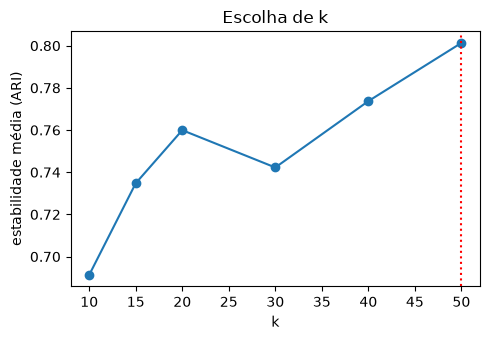

In [5]:
def detectar_comunidades(g, seed=0):
    """Leiden com ModularityVertexPartition (como no documento), não RBConfiguration com resolução."""
    return np.array(leidenalg.find_partition(g, leidenalg.ModularityVertexPartition,
                                             weights="weight", seed=seed, n_iterations=-1).membership)

def estabilidade_k(dist, k, n_seeds=N_SEEDS, n_sub=N_SUB):
    n = len(dist); g = construir_grafo_knn_mutuo(dist, k)
    parts = [detectar_comunidades(g, s) for s in range(n_seeds)]
    a = np.mean([adjusted_rand_score(parts[p], parts[q]) for p in range(n_seeds) for q in range(p + 1, n_seeds)])
    rs = np.random.default_rng(SEED); subs = []
    for _ in range(n_sub):
        idx = np.sort(rs.choice(n, int(0.9 * n), replace=False))
        ds = dist[np.ix_(idx, idx)]; gs = construir_grafo_knn_mutuo(ds, k)
        subs.append(adjusted_rand_score(parts[0][idx], detectar_comunidades(gs, 0)))
    return dict(k=k, ari_sementes=a, ari_subamostra=np.mean(subs), media=(a + np.mean(subs)) / 2)

tab_k = pd.DataFrame([estabilidade_k(dist, k) for k in K_LIST])
K = int(tab_k.loc[tab_k["media"].idxmax(), "k"]); print(f"k escolhido pela estabilidade: {K}"); display(tab_k.round(3))
plt.figure(figsize=(5, 3.5)); plt.plot(tab_k["k"], tab_k["media"], "o-"); plt.axvline(K, color="r", ls=":")
plt.xlabel("k"); plt.ylabel("estabilidade média (ARI)"); plt.title("Escolha de k"); plt.tight_layout()
plt.savefig(f"{PASTA_SAIDA}/assoc_estabilidade_k.png", dpi=150); plt.show()

## 5. Leiden com consenso e avaliação (mesmo formato de saída do colega, com testes extras)
`avaliar_comunidades` reaproveita o formato do colega (pureza, ARI, NMI, modularidade) e soma o que o documento pede: V de Cramér, assortatividade e o p-valor de 1.000 permutações do desfecho.

In [6]:
def consenso_leiden(g, n_runs=N_CONSENSO, seed0=0, max_iter=10):
    for it in range(max_iter):
        runs = np.array([detectar_comunidades(g, seed0 + s) for s in range(n_runs)])
        concorda = np.mean([adjusted_rand_score(runs[0], r) for r in runs[1:]])
        E = np.array(g.get_edgelist()); co = (runs[:, E[:, 0]] == runs[:, E[:, 1]]).mean(0)
        if concorda > 0.99 or ((co >= 0.5).all() and it > 0): break
        g = g.subgraph_edges(np.where(co >= 0.5)[0].tolist(), delete_vertices=False)
    return runs[0]

def cramer_v(memb, yy, minimo=30):
    ids, cont = np.unique(memb, return_counts=True); keep = ids[cont >= minimo]
    m = np.isin(memb, keep); idx = np.searchsorted(keep, memb[m])
    T = np.bincount(idx * NCLS + yy[m], minlength=len(keep) * NCLS).reshape(-1, NCLS).astype(float)
    T = T[:, T.sum(0) > 0]; n = T.sum(); e = T.sum(1, keepdims=True) @ T.sum(0, keepdims=True) / n
    return np.sqrt(((T - e) ** 2 / e).sum() / (n * (min(T.shape) - 1)))

def avaliar_comunidades(g, membership, rotulos, n_perm=N_PERM):
    """Mesmo formato do colega (tabela, pureza, ARI, NMI) + modularidade, V de Cramér,
    assortatividade e permutação (1.000x), como pede o documento."""
    tabela = pd.crosstab(membership, rotulos); tabela.index.name = "comunidade"; tabela.columns.name = None
    tabela["tamanho"] = tabela.sum(axis=1)
    pureza = tabela.drop(columns="tamanho").max(axis=1).sum() / len(rotulos)
    rs = np.random.default_rng(SEED)
    v_real, a_real = cramer_v(membership, y), g.assortativity_nominal(y.tolist(), directed=False)
    v_nulo, a_nulo = [], []
    for _ in range(n_perm):
        yp = rs.permutation(y); v_nulo.append(cramer_v(membership, yp)); a_nulo.append(g.assortativity_nominal(yp.tolist(), directed=False))
    p = lambda r, nulo: (1 + np.sum(np.array(nulo) >= r)) / (1 + len(nulo))
    metricas = {
        "n_comunidades": int(len(np.unique(membership))),
        "comunidades_ge30": int((tabela["tamanho"] >= 30).sum()),
        "modularidade": float(g.modularity(list(membership), weights="weight")),
        "pureza": float(pureza),
        "ARI": float(adjusted_rand_score(rotulos, membership)),
        "NMI": float(normalized_mutual_info_score(rotulos, membership)),
        "V_Cramer": float(v_real), "V_max_nulo": float(max(v_nulo)), "p_V": float(p(v_real, v_nulo)),
        "assortatividade": float(a_real), "assort_max_nulo": float(max(a_nulo)), "p_assort": float(p(a_real, a_nulo)),
    }
    return metricas, tabela

## 6. Visualização (mesmo layout em 3 painéis do colega)

In [7]:
def _desenhar_grafo(ax, g, pos, cores, titulo):
    segmentos = [(pos[a], pos[b]) for a, b in g.get_edgelist()]
    ax.add_collection(LineCollection(segmentos, colors="#999999", linewidths=0.2, alpha=0.12, zorder=1))
    ax.scatter(pos[:, 0], pos[:, 1], c=cores, s=6, linewidths=0, zorder=2)
    ax.set_title(titulo, fontsize=11, wrap=True); ax.axis("off")

def visualizar_comunidades(g, membership, rotulos, tabela, caminho_png, seed=42, minimo=30):
    """Só as comunidades com >= `minimo` alunos recebem cor própria e rótulo; o resto some num
    cinza de fundo (eram elas, muitas com 1-2 alunos, que deixavam o desenho anterior ilegível).
    O gráfico de barras também mostra só as comunidades grandes, já ordenadas pela evasão."""
    random.seed(seed); g_aux = g.copy(); w = np.array(g.es["weight"])
    intra = np.array([membership[a] == membership[b] for a, b in g.get_edgelist()])
    g_aux.es["weight"] = list(np.where(intra, 5 * w ** 2, 0.05 * w))
    layout = g_aux.layout_fruchterman_reingold(weights="weight", niter=500, seed=None)
    try: layout = g_aux.layout_graphopt(niter=800, seed=layout.coords) if g.vcount() < 6000 else layout
    except Exception: pass
    pos = np.array(layout.coords)
    tamanhos = tabela["tamanho"]; grandes = sorted(tamanhos[tamanhos >= minimo].index, key=lambda c: -tamanhos[c])
    cmap = plt.get_cmap("tab20"); cor_de = {c: cmap(k % 20) for k, c in enumerate(grandes)}
    cores_com = [cor_de.get(c, "#d9d9d9") for c in membership]
    cores_alvo = [CORES_ALVO.get(r, "#7f7f7f") for r in rotulos]
    fig = plt.figure(figsize=(20, 7))
    ax1 = fig.add_subplot(1, 3, 1); _desenhar_grafo(ax1, g, pos, cores_com, f"Comunidades de Leiden ({len(grandes)} com >= {minimo} alunos, de {tabela.shape[0]} no total) - associação")
    for c in grandes:
        centro = np.median(pos[membership == c], axis=0)
        ax1.text(*centro, str(c), fontsize=10, weight="bold", ha="center", va="center", bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.85), zorder=5)
    ax2 = fig.add_subplot(1, 3, 2); _desenhar_grafo(ax2, g, pos, cores_alvo, "Mesmo grafo colorido pela situação real")
    for nome, cor in CORES_ALVO.items():
        if nome in set(rotulos): ax2.scatter([], [], c=cor, label=nome, s=30)
    ax2.legend(loc="lower right")
    ax3 = fig.add_subplot(1, 3, 3); prop = tabela.loc[grandes].drop(columns="tamanho")
    prop = prop.div(prop.sum(axis=1), axis=0) * 100; prop = prop[[c for c in CLASSES if c in prop.columns]]
    ordem = prop[CLASSES[0]].sort_values(ascending=False).index if CLASSES[0] in prop.columns else prop.index
    prop = prop.loc[ordem]
    prop.plot(kind="bar", stacked=True, ax=ax3, color=[CORES_ALVO[c] for c in prop.columns], width=0.8)
    for xi, c in enumerate(ordem): ax3.text(xi, 102, f"n={tamanhos[c]}", ha="center", va="bottom", rotation=90, fontsize=7)
    ax3.set_ylim(0, 118); ax3.set_title(f"Composição das {len(grandes)} comunidades com >= {minimo} alunos (%)"); ax3.set_xlabel("Comunidade"); ax3.set_ylabel("% de alunos")
    ax3.legend(loc="lower center", bbox_to_anchor=(0.5, -0.3), ncol=len(prop.columns))
    if len(tamanhos) - len(grandes) > 0:
        fig.text(0.5, 0.01, f"{len(tamanhos) - len(grandes)} comunidades com menos de {minimo} alunos aparecem em cinza no grafo, sem rótulo e fora do gráfico de barras.", ha="center", fontsize=9, style="italic")
    plt.tight_layout(rect=[0, 0.04, 1, 1]); fig.savefig(caminho_png, dpi=150); plt.close(fig)

## 7. Executar: Associação + Leiden

[Associação+Leiden] Nós: 3630 | Arestas: 40521

=== Resultados Associação + Leiden ===
     n_comunidades: 49
  comunidades_ge30: 15
      modularidade: 0.7806
            pureza: 0.7882
               ARI: 0.0594
               NMI: 0.1339
          V_Cramer: 0.6200
        V_max_nulo: 0.1028
               p_V: 0.0010
   assortatividade: 0.5875
   assort_max_nulo: 0.0157
          p_assort: 0.0010

Composição por comunidade:
            Dropout  Graduate  tamanho
comunidade                            
0                60       437      497
1               231       223      454
2                80       345      425
3               267        65      332
4                24       289      313
5                71       168      239
6               227         2      229
7                32       182      214
8               172        25      197
9                13       174      187
10               32       115      147
11               69        70      139
12               72    

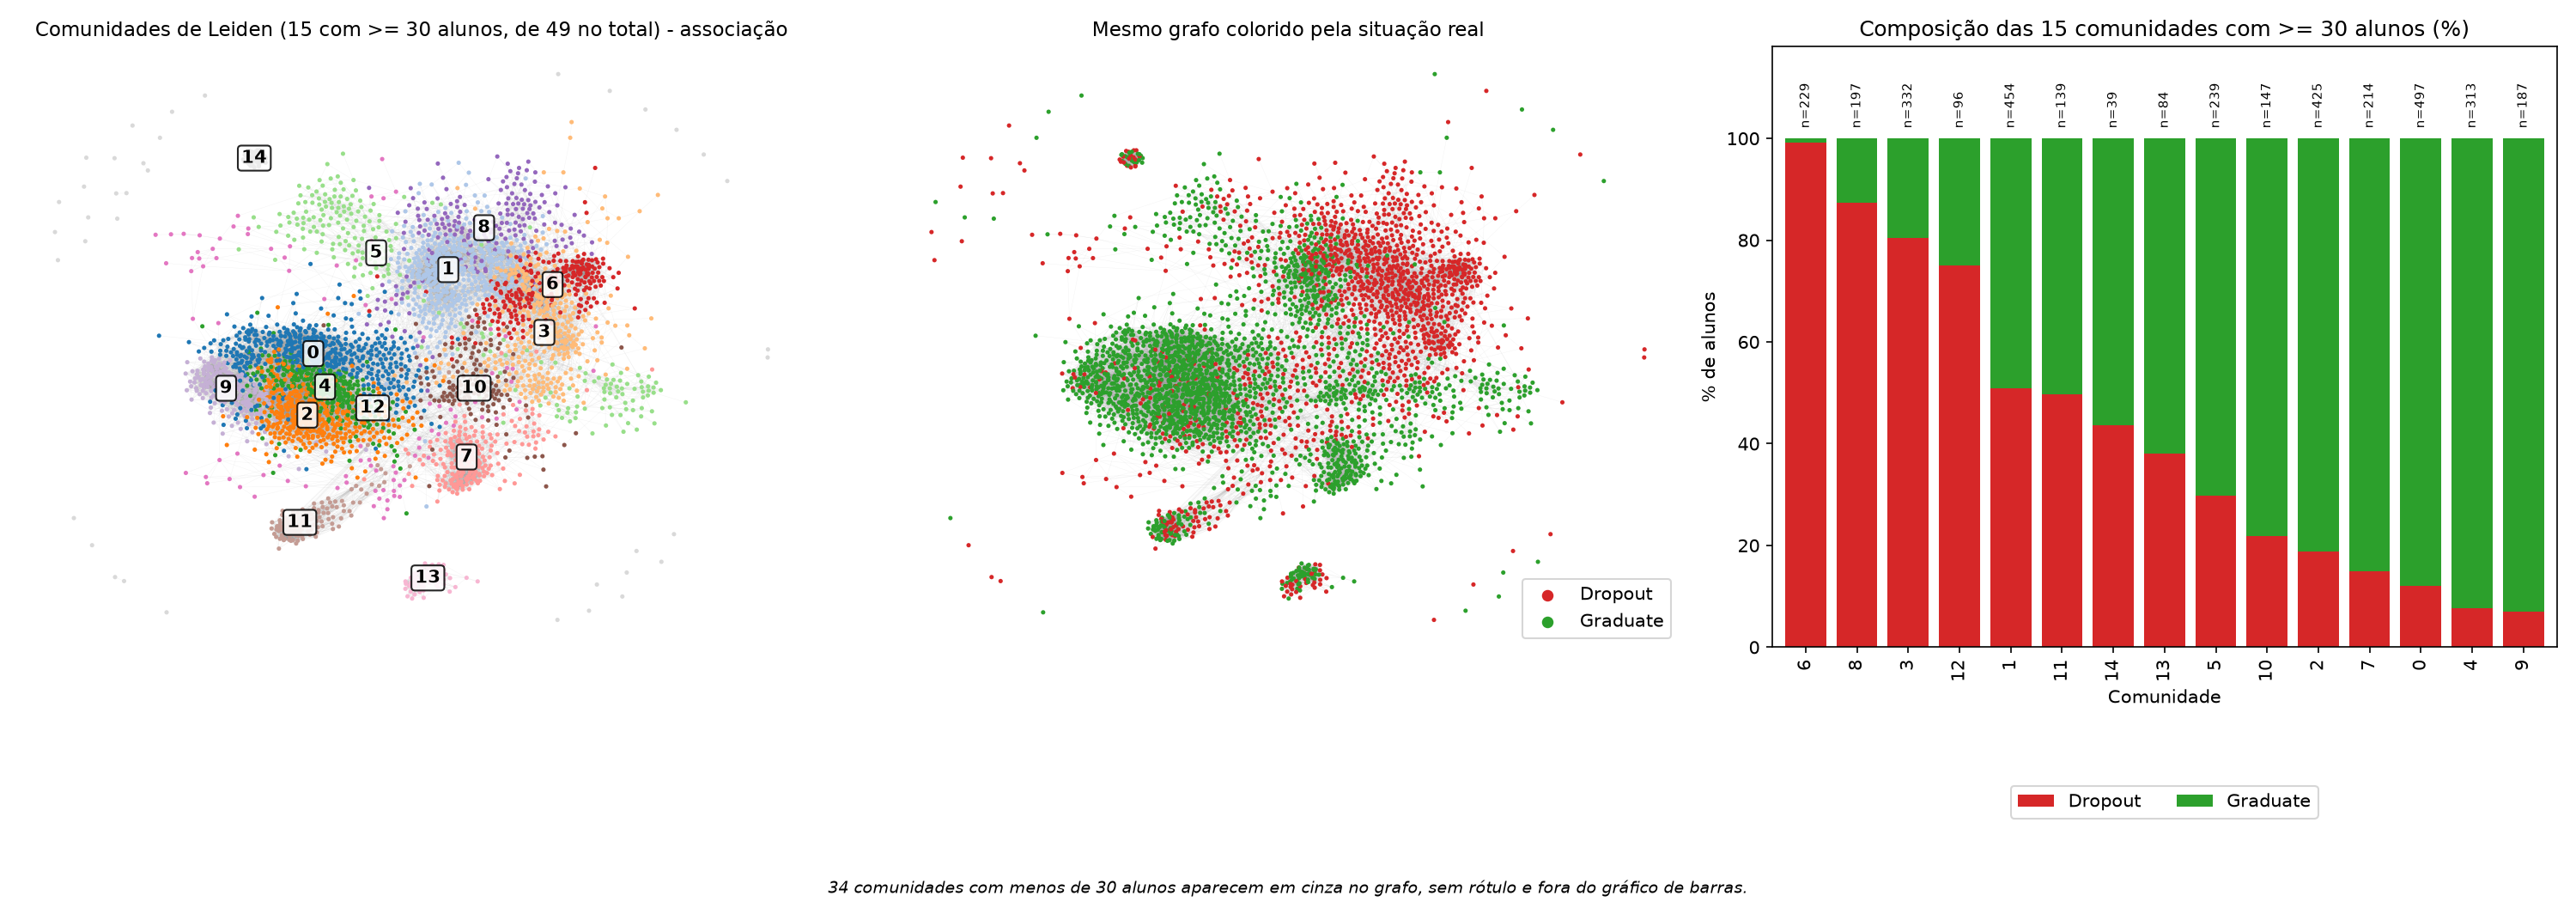

,Dropout,Graduate,tamanho
comunidade,,,
0,60,437,497
1,231,223,454
2,80,345,425
3,267,65,332
4,24,289,313
5,71,168,239
6,227,2,229
7,32,182,214
8,172,25,197


In [8]:
def executar_associacao_leiden(df, dist, k, pasta_saida=PASTA_SAIDA, seed=42):
    os.makedirs(pasta_saida, exist_ok=True)
    g = construir_grafo_knn_mutuo(dist, k)
    print(f"[Associação+Leiden] Nós: {g.vcount()} | Arestas: {g.ecount()}")
    membership = consenso_leiden(g, seed0=seed)
    metricas, tabela = avaliar_comunidades(g, membership, df["Target"].values)
    print("\n=== Resultados Associação + Leiden ===")
    for nome, valor in metricas.items():
        print(f"{nome:>18}: {valor:.4f}" if isinstance(valor, float) else f"{nome:>18}: {valor}")
    print("\nComposição por comunidade:"); print(tabela.to_string())
    png = os.path.join(pasta_saida, "assoc_leiden_comunidades.png")
    visualizar_comunidades(g, membership, df["Target"].values, tabela, png, seed=seed)
    tabela.to_csv(os.path.join(pasta_saida, "assoc_leiden_composicao.csv"))
    pd.DataFrame({"aluno": np.arange(len(df)), "comunidade": membership, "situacao": df["Target"].values}
                ).to_csv(os.path.join(pasta_saida, "assoc_leiden_comunidade_por_aluno.csv"), index=False)
    print(f"[Associação+Leiden] Figura salva em: {png}")
    return {"grafo": g, "membership": membership, "metricas": metricas, "tabela": tabela}

res_assoc = executar_associacao_leiden(df, dist, K, seed=SEED)
display(Image(f"{PASTA_SAIDA}/assoc_leiden_comunidades.png"))
res_assoc["tabela"]

> **Como ler:** à esquerda, as comunidades; no meio, o mesmo grafo colorido pela situação real; à direita, a composição de cada comunidade (% Dropout/Enrolled/Graduate), com o tamanho (n) no topo.

## 8. Perfis das comunidades (rótulo curto + tabela completa)

In [9]:
def rotulo_curto(df, memb, c, cats, nums, minimo=30):
    m = memb == c
    if m.sum() < minimo: return ""
    z = (df[nums] - df[nums].mean()) / df[nums].std(); zc = z[m].mean()
    melhor_num = zc.abs().idxmax(); cand = [(abs(zc[melhor_num]), f"{melhor_num} {zc[melhor_num]:+.1f}dp")]
    for v in cats:
        s_ = df.loc[m, v].value_counts(normalize=True); base_v = df[v].value_counts(normalize=True)
        for val, sh in s_.items():
            if sh >= 0.5 and sh / base_v[val] >= 1.3: cand.append((sh / base_v[val], f"{v}={val} ({sh:.0%})"))
    cand.sort(key=lambda t: -t[0]); return cand[0][1] if cand else ""

def perfil_comunidades(df, memb, cats, nums, minimo=30):
    z = (df[nums] - df[nums].mean()) / df[nums].std(); rows = []
    for c in np.unique(memb):
        m = memb == c
        if m.sum() < minimo: continue
        zc = z[m].mean(); zc = zc.reindex(zc.abs().sort_values(ascending=False).index).head(3)
        rows.append(dict(comunidade=c, alunos=int(m.sum()),
                         **{cl: round((y[m] == i).mean(), 3) for i, cl in enumerate(CLASSES)},
                         numericas="; ".join(f"{k} {v:+.1f}dp" for k, v in zc.items()),
                         rotulo_curto=rotulo_curto(df, memb, c, cats, nums, minimo)))
    return pd.DataFrame(rows).sort_values("Dropout", ascending=False).reset_index(drop=True)

perfis = perfil_comunidades(df, res_assoc["membership"], cats, nums)
display(perfis); perfis.to_csv(f"{PASTA_SAIDA}/assoc_leiden_perfis.csv", index=False)

,comunidade,alunos,Dropout,Graduate,numericas,rotulo_curto
0,6,229,0.991,0.009,Curricular units 1st sem (grade) -2.0dp; Curri...,Curricular units 1st sem (grade) -2.0dp
1,8,197,0.873,0.127,Curricular units 2nd sem (grade) -1.2dp; Curri...,Curricular units 2nd sem (grade) -1.2dp
2,3,332,0.804,0.196,Curricular units 2nd sem (approved) -0.5dp; Cu...,Debtor=1 (81%)
3,12,96,0.750,0.250,Curricular units 2nd sem (without evaluations)...,Curricular units 2nd sem (without evaluations)...
4,1,454,0.509,0.491,Age at enrollment +1.5dp; Application order -0...,Daytime/evening attendance=0 (56%)
5,11,139,0.496,0.504,Curricular units 2nd sem (enrolled) -2.8dp; Cu...,Curricular units 2nd sem (enrolled) -2.8dp
6,14,39,0.436,0.564,Unemployment rate +0.5dp; Curricular units 1st...,Educational special needs=1 (100%)
7,13,84,0.381,0.619,Previous qualification (grade) +0.4dp; Applica...,International=1 (100%)
8,5,239,0.297,0.703,Curricular units 1st sem (credited) +3.1dp; Cu...,Curricular units 1st sem (credited) +3.1dp
9,10,147,0.218,0.782,Admission grade +0.9dp; Curricular units 2nd s...,Application mode=44 (60%)


## 9. Regras de associação (mlxtend, mesma ferramenta do colega)
Quais características, isoladas ou em pares, mais aparecem entre os alunos de cada comunidade e de cada desfecho real — usando a mesma biblioteca (`apriori`/`association_rules`) que o colega usou na GNN dele.

In [10]:
def construir_itens(df, colunas, rotulo):
    itens = {}
    for c in colunas:
        s = df[c]
        if c in COLUNAS_CATEGORICAS:               # nominal: um item por categoria, nunca faixas
            for v in sorted(s.astype(str).unique()):
                cont = (s.astype(str) == v).sum()
                if cont >= 30: itens[f"{c}={v}"] = (s.astype(str) == v).values
        elif s.nunique() <= 2:
            for v in sorted(s.unique()): itens[f"{c}={int(v) if float(v).is_integer() else v}"] = (s == v).values
        else:
            faixas = pd.qcut(s, q=4, duplicates="drop")
            for iv in faixas.cat.categories: itens[f"{c} em [{iv.left:.1f}; {iv.right:.1f}]"] = (faixas == iv).values
    for cl in np.unique(rotulo): itens[f"Alvo={cl}"] = rotulo == cl
    return pd.DataFrame(itens, index=df.index)

def minerar_associacoes(df, rotulo, colunas, min_support=0.05, min_conf=0.5, max_len=3):
    base = construir_itens(df, colunas, np.asarray(rotulo))
    freq = apriori(base, min_support=min_support, use_colnames=True, max_len=max_len)
    regras = association_rules(freq, num_itemsets=len(base), metric="confidence", min_threshold=min_conf)
    so_alvo = regras.apply(lambda r: len(r["consequents"]) == 1 and next(iter(r["consequents"])).startswith("Alvo=")
                           and not any(i.startswith("Alvo=") for i in r["antecedents"]), axis=1)
    regras = regras[so_alvo].copy(); regras["classe"] = regras["consequents"].apply(lambda s: next(iter(s)).replace("Alvo=", ""))
    regras["perfil"] = regras["antecedents"].apply(lambda s: " E ".join(sorted(s)))
    return regras[["perfil", "classe", "support", "confidence", "lift"]].sort_values(["classe", "lift"], ascending=[True, False]).reset_index(drop=True)

colunas_regras = [c for c in COLUNAS_CATEGORICAS + COLUNAS_NUMERICAS if c != "Course"]
regras_assoc = minerar_associacoes(df, df["Target"].values, colunas_regras)
print(f"{len(regras_assoc)} regras encontradas"); display(regras_assoc.groupby("classe").head(6).round(3))
regras_assoc.to_csv(f"{PASTA_SAIDA}/assoc_regras_associacao.csv", index=False)

2399 regras encontradas


,perfil,classe,support,confidence,lift
0,Age at enrollment em [25.0; 70.0] E Curricular...,Dropout,0.114,0.993,2.536
1,Curricular units 1st sem (enrolled) em [5.0; 6...,Dropout,0.106,0.992,2.535
2,Curricular units 2nd sem (approved) em [-0.0; ...,Dropout,0.104,0.992,2.534
3,Age at enrollment em [25.0; 70.0] E Tuition fe...,Dropout,0.064,0.992,2.533
4,Curricular units 1st sem (approved) em [-0.0; ...,Dropout,0.088,0.991,2.531
5,Curricular units 2nd sem (approved) em [-0.0; ...,Dropout,0.087,0.991,2.531
458,Curricular units 1st sem (approved) em [6.0; 2...,Graduate,0.067,0.976,1.604
459,Curricular units 2nd sem (approved) em [6.0; 2...,Graduate,0.075,0.975,1.602
460,Curricular units 2nd sem (approved) em [5.0; 6...,Graduate,0.054,0.966,1.587
461,Curricular units 2nd sem (grade) em [13.5; 18....,Graduate,0.080,0.964,1.583


## 10. Sensibilidade e robustez (itens pendentes da modelagem)
- **Curso dentro ou fora da distância:** refazemos incluindo "Course" entre as categóricas.
- **Curso 171:** refazemos sem os alunos desse curso.
- **Robustez por subgrupo:** a separação (V de Cramér) vale igual em cada subgrupo de gênero, turno e faixa de idade?

In [11]:
def roda_variacao(cats_, nums_, filtro=None, k=None):
    dfx = df.copy() if filtro is None else df[filtro].reset_index(drop=True)
    yx = y if filtro is None else y[filtro]
    for _c in cats_:    # mesma regra de categorias raras, válida também para "Course" quando entra na distância
        _contagem = dfx[_c].value_counts(); _raras = _contagem[_contagem < MIN_CATEGORIA].index
        if len(_raras): dfx[_c] = dfx[_c].where(~dfx[_c].isin(_raras), "Outros")
    d, _ = calcular_distancia_associacao(dfx, cats_, nums_)
    kk = k or K
    g = construir_grafo_knn_mutuo(d, kk); memb = consenso_leiden(g, seed0=SEED)
    tabela = pd.crosstab(memb, dfx["Target"].values); tabela["tamanho"] = tabela.sum(1)
    pureza_curso = np.nan
    if "Course" in dfx.columns:
        pureza_curso = pd.crosstab(memb, dfx["Course"]).div(tabela["tamanho"], axis=0).max(1).mean()
    return dict(comunidades_ge30=int((tabela["tamanho"] >= 30).sum()), modularidade=g.modularity(list(memb), weights="weight"),
                V_Cramer=cramer_v(memb, yx), assortatividade=g.assortativity_nominal(yx.tolist(), directed=False), pureza_curso=pureza_curso)

print("Rodando sensibilidade (pode levar alguns minutos)...")
sens = pd.DataFrame({
    "principal (sem curso)": roda_variacao(cats, nums),
    "com curso na distância": roda_variacao(cats + ["Course"], nums),
    "sem curso 171": roda_variacao(cats, nums, filtro=(df["Course"] != 171).values),
}).T
display(sens.round(3)); sens.to_csv(f"{PASTA_SAIDA}/assoc_sensibilidade.csv")

Rodando sensibilidade (pode levar alguns minutos)...


,comunidades_ge30,modularidade,V_Cramer,assortatividade,pureza_curso
principal (sem curso),15.0,0.781,0.620,0.588,0.771
com curso na distância,16.0,0.788,0.619,0.584,0.784
sem curso 171,15.0,0.758,0.627,0.622,0.776


In [12]:
def robustez_subgrupo(memb):
    grupos = {"Gênero=0": df["Gender"].values == 0, "Gênero=1": df["Gender"].values == 1,
             "Turno=0": df["Daytime/evening attendance"].values == 0, "Turno=1": df["Daytime/evening attendance"].values == 1,
             "Idade <25": df["Age at enrollment"].values < 25, "Idade 25+": df["Age at enrollment"].values >= 25}
    rows = []
    for nome, m in grupos.items():
        if m.sum() < 30: rows.append((nome, int(m.sum()), np.nan)); continue
        rows.append((nome, int(m.sum()), round(cramer_v(memb[m], y[m]), 3) if len(np.unique(memb[m])) > 1 else np.nan))
    return pd.DataFrame(rows, columns=["subgrupo", "n", "V_Cramer"])

rob = robustez_subgrupo(res_assoc["membership"]); display(rob); rob.to_csv(f"{PASTA_SAIDA}/assoc_robustez_subgrupo.csv", index=False)

,subgrupo,n,V_Cramer
0,Gênero=0,2381,0.620
1,Gênero=1,1249,0.577
2,Turno=0,408,0.196
3,Turno=1,3222,0.651
4,Idade <25,2654,0.622
5,Idade 25+,976,0.460


## 11. Como ler e escrever no artigo
* Esta variação é **Associação + Leiden**, com kNN **mútuo** (diferente do kNN do colega) e a distância por associação de verdade (diferente de reaproveitar o Gower).
* `USAR_JANELAS = False` por padrão, igual à estrutura do colega — mude para `True` se o grupo decidir seguir a Regra 1 (janelas de tempo) do documento à risca; nesse caso rode a célula de execução uma vez por janela.
* A tabela de sensibilidade (seção 10) responde as perguntas do documento que estavam pendentes: curso dentro/fora, curso 171 e robustez por subgrupo.
* Lembrar: *associação não é causa*; "Enrolled" = atraso, não sucesso; perfil de risco serve para apoiar, nunca para rotular.

Arquivos gerados em `resultados/`: `assoc_leiden_*.csv/png`, `assoc_regras_associacao.csv`, `assoc_sensibilidade.csv`, `assoc_robustez_subgrupo.csv`.